<a href="https://colab.research.google.com/github/emmanresu/Thesis-Keras/blob/feature%2Fprototype/EDA_indian_food_prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Exploratory Data Analysis of Indian rice prices

Dataset link: https://data.humdata.org/dataset/wfp-food-prices-for-india

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from numpy import where
from numpy import astype
from numpy import float64

In [ ]:
prices = pd.read_csv('wfp_food_prices_ind.csv')
prices

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,1994-01-15,Delhi,Delhi,Delhi,934,28.67,77.22,cereals and tubers,Rice,52,KG,actual,Retail,INR,8.00,0.26
1,1994-01-15,Delhi,Delhi,Delhi,934,28.67,77.22,cereals and tubers,Wheat,84,KG,actual,Retail,INR,5.00,0.16
2,1994-01-15,Delhi,Delhi,Delhi,934,28.67,77.22,miscellaneous food,Sugar,97,KG,actual,Retail,INR,13.50,0.43
3,1994-01-15,Delhi,Delhi,Delhi,934,28.67,77.22,oil and fats,Oil (mustard),228,KG,actual,Retail,INR,31.00,0.99
4,1994-01-15,Gujarat,Ahmadabad,Ahmedabad,923,23.03,72.62,cereals and tubers,Rice,52,KG,actual,Retail,INR,6.80,0.22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
206087,2026-05-15,Rajasthan,Jaipur,North Zone,9638,26.94,75.80,vegetables and fruits,Eggplants,434,KG,actual,Retail,INR,35.35,0.37
206088,2026-05-15,Rajasthan,Jaipur,North Zone,9638,26.94,75.80,vegetables and fruits,Garlic,105,KG,actual,Retail,INR,34.86,0.36
206089,2026-05-15,Rajasthan,Jaipur,North Zone,9638,26.94,75.80,vegetables and fruits,Ginger,712,KG,actual,Retail,INR,27.01,0.28
206090,2026-05-15,Rajasthan,Jaipur,North Zone,9638,26.94,75.80,vegetables and fruits,Onions,173,KG,actual,Retail,INR,23.82,0.25


In [ ]:
prices.describe()

,market_id,latitude,longitude,commodity_id,price,usdprice
count,206092.000000,205366.000000,205366.000000,206092.000000,206092.000000,206092.000000
mean,2461.464074,22.369520,80.259819,189.204341,94.468171,1.391436
std,2172.446129,6.207687,5.656315,124.364190,213.563321,3.638336
min,921.000000,8.510000,69.670000,52.000000,2.500000,0.057000
25%,940.000000,18.860000,76.280000,83.000000,28.000000,0.410000
50%,962.000000,23.350000,78.160000,173.000000,52.630000,0.750000
75%,4672.000000,26.640000,84.900000,325.000000,109.000000,1.500000
max,9642.000000,32.550000,94.120000,1341.000000,4910.000000,88.820000


In [ ]:
rice_prices = prices.query('commodity == "Rice"')

In [ ]:
print(rice_prices[['date', 'market', 'unit', 'priceflag', 'price']].to_string())

              date                   market    unit priceflag    price
0       1994-01-15                    Delhi      KG    actual     8.00
4       1994-01-15                Ahmedabad      KG    actual     6.80
8       1994-01-15                   Shimla      KG    actual     9.00
11      1994-01-15                Bengaluru      KG    actual     6.50
18      1994-01-15                   Mumbai      KG    actual     7.50
22      1994-01-15             Bhubaneshwar      KG    actual     5.00
26      1994-01-15                Hyderabad      KG    actual     6.20
32      1994-01-15                  Kolkata      KG    actual     6.75
35      1994-02-15                    Delhi      KG    actual     8.00
39      1994-02-15                Ahmedabad      KG    actual     6.90
43      1994-02-15                   Shimla      KG    actual     8.75
46      1994-02-15                   Bhopal      KG    actual     6.25
49      1994-02-15                   Mumbai      KG    actual     8.00
52    

### preprocess inflated prices

In [ ]:
rice_prices[['multiplier', 'remove']] = rice_prices['unit'].str.split(' ', expand=True)
not_kg = rice_prices['multiplier'] != 'KG'
rice_prices['multiplier'] = rice_prices['multiplier'].where(not_kg, 1)
rice_prices['multiplier'] = rice_prices['multiplier'].astype(float64)
rice_prices = rice_prices.drop(columns=['remove'])

/tmp/ipykernel_2697/3378800387.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rice_prices[['multiplier', 'remove']] = rice_prices['unit'].str.split(' ', expand=True)
/tmp/ipykernel_2697/3378800387.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rice_prices[['multiplier', 'remove']] = rice_prices['unit'].str.split(' ', expand=True)
/tmp/ipykernel_2697/3378800387.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] =

In [ ]:
rice_prices['indian_rice_price'] = rice_prices.eval('price / multiplier')
rice_prices['indian_rice_price'] = round(rice_prices['new_price'], 2)

In [ ]:
print(rice_prices[['date', 'market', 'unit', 'price', 'multiplier', 'indian_rice_price']].to_string())

              date                   market    unit    price  multiplier  new_price
0       1994-01-15                    Delhi      KG     8.00         1.0       8.00
4       1994-01-15                Ahmedabad      KG     6.80         1.0       6.80
8       1994-01-15                   Shimla      KG     9.00         1.0       9.00
11      1994-01-15                Bengaluru      KG     6.50         1.0       6.50
18      1994-01-15                   Mumbai      KG     7.50         1.0       7.50
22      1994-01-15             Bhubaneshwar      KG     5.00         1.0       5.00
26      1994-01-15                Hyderabad      KG     6.20         1.0       6.20
32      1994-01-15                  Kolkata      KG     6.75         1.0       6.75
35      1994-02-15                    Delhi      KG     8.00         1.0       8.00
39      1994-02-15                Ahmedabad      KG     6.90         1.0       6.90
43      1994-02-15                   Shimla      KG     8.75         1.0    

In [ ]:
rice_prices.describe()

,market_id,latitude,longitude,commodity_id,price,usdprice,multiplier,new_price
count,14369.000000,14331.000000,14331.000000,14369.0,14369.000000,14369.000000,14369.000000,14369.000000
mean,2024.902429,22.285737,80.515806,52.0,150.274444,2.634927,7.772705,27.080766
std,1929.935331,6.153813,5.875815,0.0,499.437324,8.593943,24.993434,11.873649
min,921.000000,8.510000,69.670000,52.0,5.000000,0.140000,1.000000,5.000000
25%,935.000000,18.870000,76.640000,52.0,20.250000,0.350000,1.000000,18.000000
50%,956.000000,23.330000,78.470000,52.0,29.000000,0.420000,1.000000,27.460000
75%,1783.000000,26.470000,85.120000,52.0,37.000000,0.510000,1.000000,34.520000
max,9642.000000,32.550000,94.120000,52.0,4910.000000,67.880000,100.000000,71.830000


### Indian rice prices (aggregate)

In [ ]:
grouped_prices = rice_prices.groupby('date').agg(
    price=('price', 'mean'),
    indian_rice_price=('indian_rice_price', 'mean')
)

In [ ]:
grouped_prices['2000-01-15':grouped_prices.index.max()]

,price,new_price
date,,
2000-01-15,235.236111,10.891111
2000-02-15,213.895000,11.069000
2000-03-15,168.552632,10.934211
2000-04-15,200.420476,11.172857
2000-05-15,209.220000,10.903000
...,...,...
2026-01-15,43.430000,43.430000
2026-02-15,43.477500,43.477500
2026-03-15,42.774000,42.774000


In [ ]:
dataset = grouped_prices.reset_index()

In [ ]:
dataset.index = dataset.date

In [ ]:
dataset.loc['2000-01-15':dataset.index.max()]

,date,price,new_price
date,,,
2000-01-15,2000-01-15,235.236111,10.891111
2000-02-15,2000-02-15,213.895000,11.069000
2000-03-15,2000-03-15,168.552632,10.934211
2000-04-15,2000-04-15,200.420476,11.172857
2000-05-15,2000-05-15,209.220000,10.903000
...,...,...,...
2026-01-15,2026-01-15,43.430000,43.430000
2026-02-15,2026-02-15,43.477500,43.477500
2026-03-15,2026-03-15,42.774000,42.774000


In [ ]:
dataset = dataset.loc['2000-01-15':dataset.index.max()]

In [ ]:
dataset = dataset.reset_index(drop=True)

In [ ]:
dataset[['y','m','d']] = dataset['date'].str.split('-', expand=True)
dataset['date'] = dataset['y'] + '-' + dataset['m']
dataset = dataset.drop(columns=['y','m','d'])

TypeError: cannot do slice indexing on RangeIndex with these indexers [2000-01-15] of type str

### Visualization of Indian rice prices from 2000 to latest available date

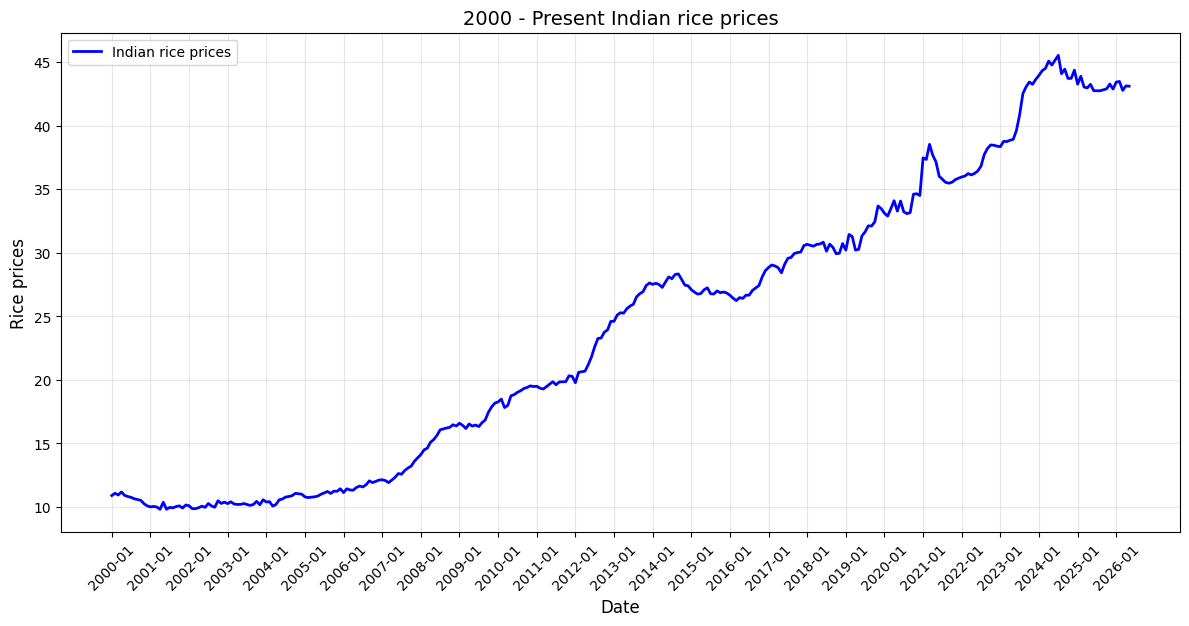

In [ ]:
# 1. Formatting the date range for the legend
start_date = dataset.index.min()
end_date = dataset.index.max()
date_range_str = f"({start_date} to {end_date})"

# 2. Plotting
plt.figure(figsize=(12, 6))

# Total rice stocks
plt.plot(dataset['date'], dataset['indian_rice_price'], label=f'Indian rice prices', color='blue', linewidth=2)

# 3. Aesthetics
plt.title('2000 - Present Indian rice prices', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Rice prices', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.xticks(dataset['date'][::12], rotation=45)
# dataset = dataset.drop(columns=['date'])
plt.show()

### Correlation matrix

In [ ]:
ph_dataset = pd.read_csv('dataset.csv')

In [ ]:
corr_matrix = ph_dataset.drop(columns=['date']).corr()

plt.figure(figsize=(6,  4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')

### Tests

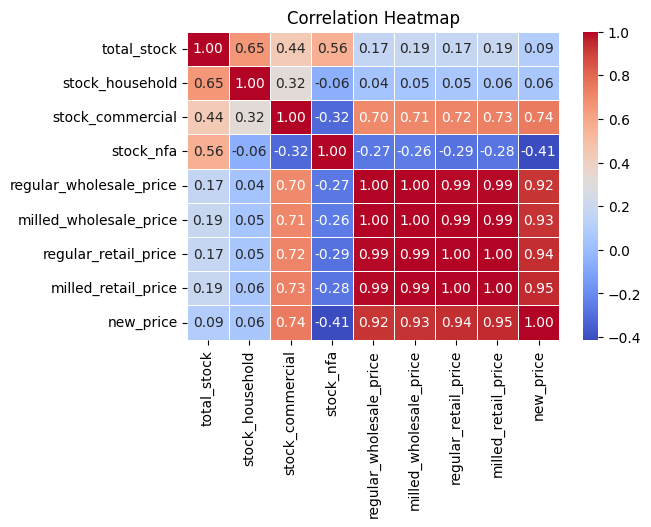

In [ ]:
corr_matrix = ph_dataset.drop(columns=['date']).corr()

plt.figure(figsize=(6,  4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show('correlation_plot.png')